# Individual homework project 1

In [3]:
#Importmodules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Import data

customers = pd.read_csv("data/customers.csv")
transactions = pd.read_csv("data/transactions.csv")
sessions = pd.read_csv("data/web_sessions.csv")
campaigns = pd.read_csv("data/campaign_touchpoints.csv")



In [72]:
customers.head()
transactions.head()
#sessions.head()
#campaigns.head()

,transaction_id,customer_id,product_category,purchase_value,discount_used,purchase_date,is_refunded,refund_date,refund_reason
0,1,8141,home,380.95,0,2023-09-05,0,NaN,NaN
1,2,1297,fashion,67.08,0,2019-08-07,0,NaN,NaN
2,3,7930,toys,43.37,1,2020-02-07,1,1.581898e+18,late_delivery
3,4,2426,electronics,1191.45,0,2020-10-02,0,NaN,NaN
4,5,6614,fashion,112.21,0,2023-09-15,0,NaN,NaN


### Specific questions

Q1. What is the average purchase value for customers from Spain?

In [26]:

#merge the transactions and customers DataFrames on the 'customer_id' column
merged = pd.merge(transactions, customers, on='customer_id', how='inner')

#calculating the average purchase value for Spain
avg_purchase_value = round(merged['purchase_value'][merged['country'] == 'Spain'].mean(), 2)

#printing the value
print(f"The average purchase value for Spain is: {avg_purchase_value}")

The average purchase value for Spain is: 230.96


Q2. What is the minimum purchase value for customers from Germany?

In [27]:

#merge the transactions and customers DataFrames on the 'customer_id' column
merged = pd.merge(transactions, customers, on='customer_id', how='inner')

#calculating the minimum purchase value for Germany
min_purchase_value = round(merged['purchase_value'][merged['country'] == 'Germany'].min(), 2)

#printing the value
print(f"The minimum purchase value for Germany is: {min_purchase_value}")

The minimum purchase value for Germany is: 10.01


Q3. How much did males spend on buying products in the Sports category?

In [36]:
#merge the transactions and customers DataFrames on the 'customer_id' column
merged = pd.merge(transactions, customers, on='customer_id', how='inner')

#calculating Sport category spend for Male
#merged.groupby(['gender', 'product_category'])['purchase_value'].sum()

filtered_data = merged[(merged['gender'] == 'Male') & (merged['product_category'] == 'sports')]
sport_spend_male = filtered_data['purchase_value'].sum()

#sport_spend_male = merged.groupby(['gender', 'product_category'])['purchase_value'].sum().loc[("Male", "sports")] - index label based and not position based

print(f"The total Sport category spend for Male is: {sport_spend_male}")

The total Sport category spend for Male is: 404877.87


Q4. What is the average age of female customers from Canada?

In [50]:
#merge the transactions and customers DataFrames on the 'customer_id' column
merged = pd.merge(transactions, customers, on='customer_id', how='inner')

#merged.head()

#calculating the average age of Female customers in Canada
filtered_data = merged[(merged['gender']== 'Female') & (merged['country']== 'Canada')]
avg_age_female_canada = round(filtered_data['age'].mean(), 2)
#print(filtered_data)
print(f"The average age of Female customers in Canada is: {avg_age_female_canada}")


The average age of Female customers in Canada is: 43.07


Q5. How much does an average male customer from the UK spend?

In [51]:
#merge the transactions and customers DataFrames on the 'customer_id' column
merged = pd.merge(transactions, customers, on='customer_id', how='inner')

#calculating the average male purchase value for UK
filtered_data = merged[(merged['gender']== 'Male') & (merged['country']== 'UK')]
avg_male_purchase_uk = round(filtered_data['purchase_value'].mean(), 2)
print(f"The average male purchase value for UK is: {avg_male_purchase_uk}")

The average male purchase value for UK is: 234.48


Q6. What is the maximum purchase value for females in the Toys category?

In [52]:
#merge the transactions and customers DataFrames on the 'customer_id' column
merged = pd.merge(transactions, customers, on='customer_id', how='inner')

#calculating the maximum purchase value for Females in Toys category
filtered_data = merged[(merged['gender']== 'Female') & (merged['product_category']== 'toys')]
max_purchase_value_female_toys = round(filtered_data['purchase_value'].max(), 2)
print(f"The maximum purchase value for Females in Toys category is: {max_purchase_value_female_toys}")


The maximum purchase value for Females in Toys category is: 79.99


Q7. What is the average number of pages viewed for customers who made a purchase (converted)?

In [61]:

#calculating the average number of pages of Customers who made a purchase

avg_pages_viewed = round(sessions['pages_viewed'][(sessions['converted']== 1)].mean(), 2)
print("Average pages viewed by converted customers:", avg_pages_viewed)

Average pages viewed by converted customers: 5.73


Q8. What is the average time spent on the site for purchasing vs non-purchasing customers?

In [66]:
#sessions.head()

#calculating the average time spent on site, grouped by whether the customer made a purchase or not
avg_time_spent = round(sessions.groupby('converted')['time_on_site'].mean(), 2)

print("Average time spent on site by purchasing customers:", avg_time_spent[1])
print("Average time spent on site by non-purchasing customers:", avg_time_spent[0])

Average time spent on site by purchasing customers: 311.19
Average time spent on site by non-purchasing customers: 299.24


### Visualisation tasks

Q9. Plot purchasing value across years.

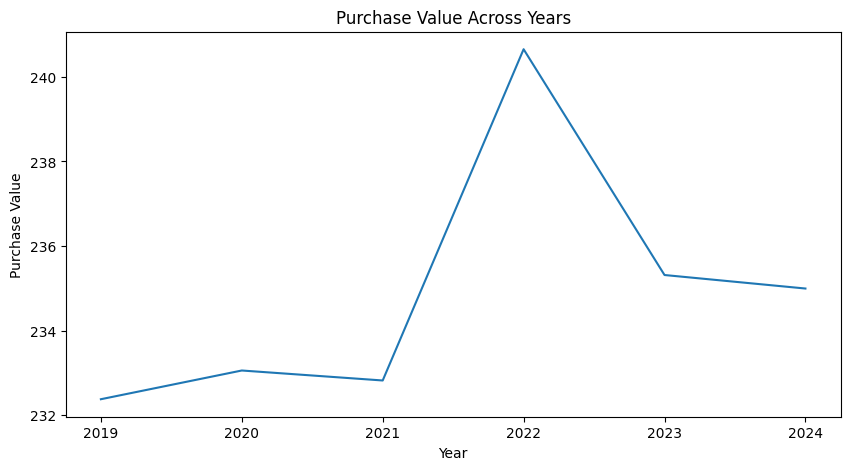

In [87]:
plt.figure(figsize=(10, 5))

transactions['purchase_date'] = pd.to_datetime(transactions['purchase_date'])
year = transactions['purchase_date'].dt.year
sns.lineplot(x=year, y=transactions['purchase_value'], errorbar=None)
plt.title('Purchase Value Across Years')
plt.xlabel('Year')
plt.ylabel('Purchase Value')
plt.show()


Q10. Plot purchasing value across product categories.

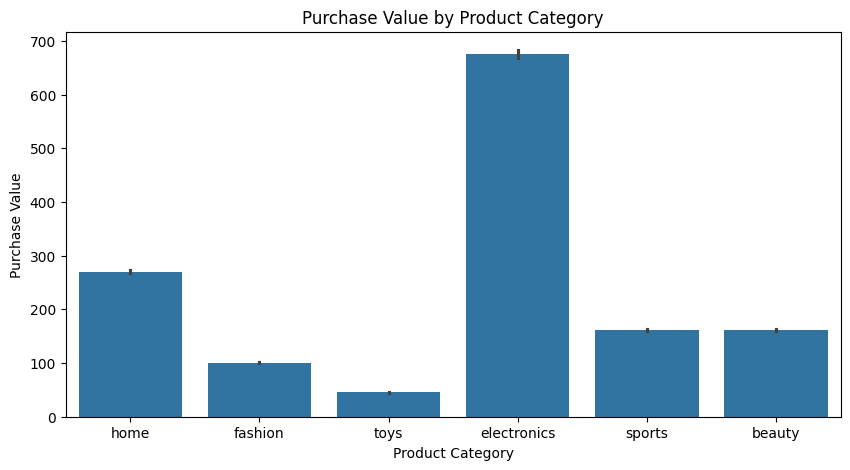

In [88]:
merged = pd.merge(transactions, customers, on='customer_id', how='inner')

plt.figure(figsize=(10, 5))
sns.barplot(x='product_category', y='purchase_value', data=merged)
plt.title('Purchase Value by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Purchase Value')
plt.show()

### Free exercise

Explore the transactions dataset and:

- Create two visualisations of your choice
- Identify three patterns in the data
- Write five insights in plain English explaining what the data tells us

Your insights should focus on behaviour, spending patterns, or conversion

### Free exercise - Solutions

**Customer analysis - age, gender and country wise**


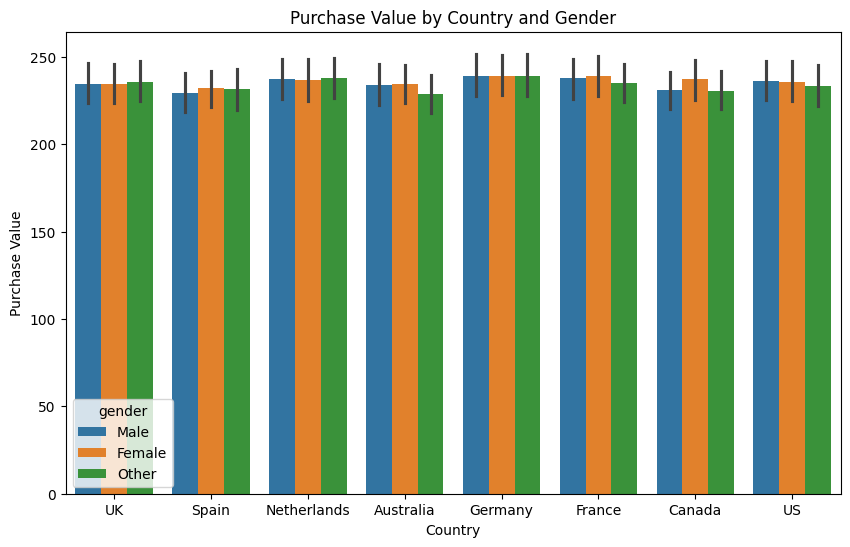

In [172]:
merged = pd.merge(transactions, customers, on='customer_id', how='inner')

plt.figure(figsize=(10, 6))
sns.barplot(x='country', y='purchase_value', hue='gender', data=merged)
plt.title('Purchase Value by Country and Gender')
plt.xlabel('Country')
plt.ylabel('Purchase Value')
plt.show()

age_group
18-25    236.264152
46-55    235.931810
55+      234.603874
36-45    234.549081
<18      233.542895
26-35    230.815111
Name: purchase_value, dtype: float64


C:\Users\shubh\AppData\Local\Temp\ipykernel_13428\1401308633.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  highest_purchase_age_group = merged.groupby('age_group')['purchase_value'].mean().sort_values(ascending=False)#.head(1)


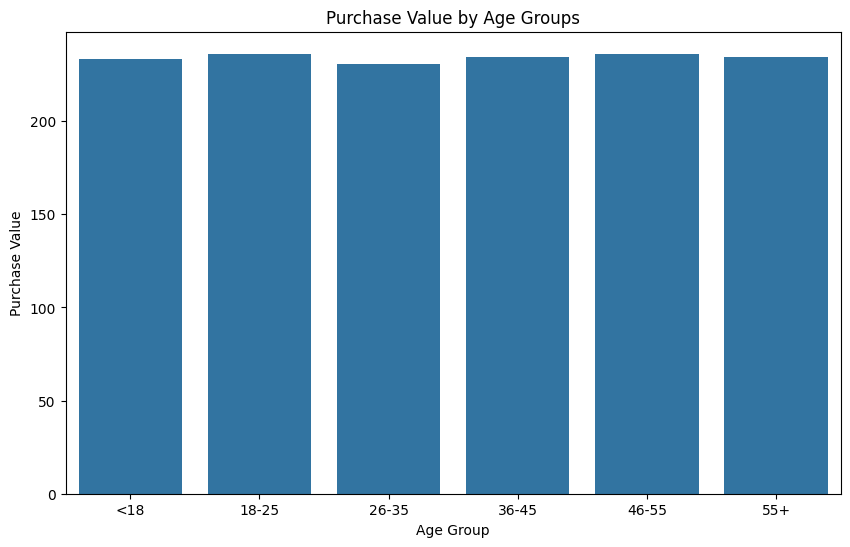

In [173]:
#Purchase Value by Age Groups - Data shows the values are similar across age groups, with age group 18-25 being highest
merged = pd.merge(transactions, customers, on='customer_id', how='inner')

# Create age buckets
merged['age_group'] = pd.cut(
                            merged['age'],
                            bins=[0, 18, 25, 35, 45, 55, 100],
                            labels=['<18', '18-25', '26-35', '36-45', '46-55', '55+']
                            )


highest_purchase_age_group = merged.groupby('age_group')['purchase_value'].mean().sort_values(ascending=False)#.head(1)
print(highest_purchase_age_group)

plt.figure(figsize=(10, 6))
sns.barplot(x='age_group', y='purchase_value', data=merged, estimator= 'mean', errorbar=None)
plt.title('Purchase Value by Age Groups')
plt.xlabel('Age Group')
plt.ylabel('Purchase Value')
plt.show()

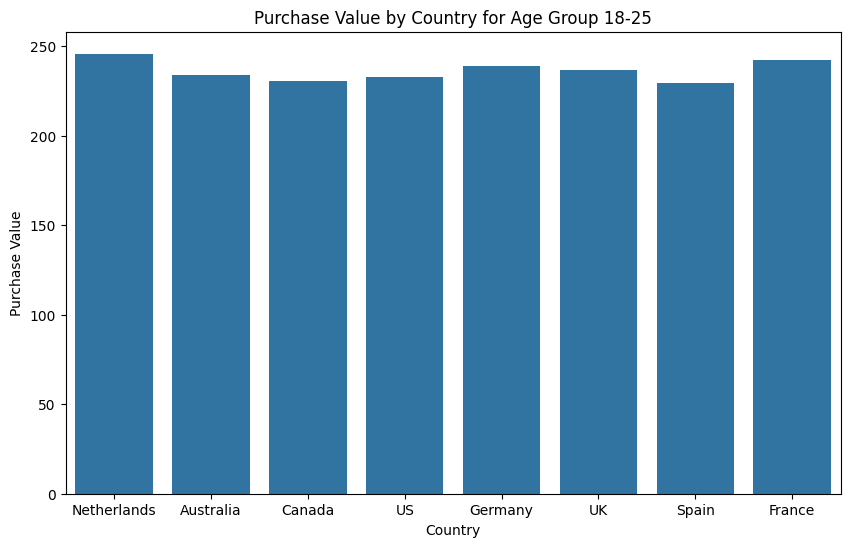

In [174]:
# Where are the Age group 18-25 customers located ?
merged = pd.merge(transactions, customers, on='customer_id', how='inner')

# Create age buckets
merged['age_group'] = pd.cut(
                            merged['age'],
                            bins=[0, 18, 25, 35, 45, 55, 100],
                            labels=['<18', '18-25', '26-35', '36-45', '46-55', '55+']
                            )

#Plot country wise purchase value for age group 18-25
plt.figure(figsize=(10, 6))
sns.barplot(x='country', y='purchase_value', data=merged[merged['age_group'] == '18-25'], estimator= 'mean', errorbar=None)
plt.title('Purchase Value by Country for Age Group 18-25')
plt.xlabel('Country')
plt.ylabel('Purchase Value')
plt.show()

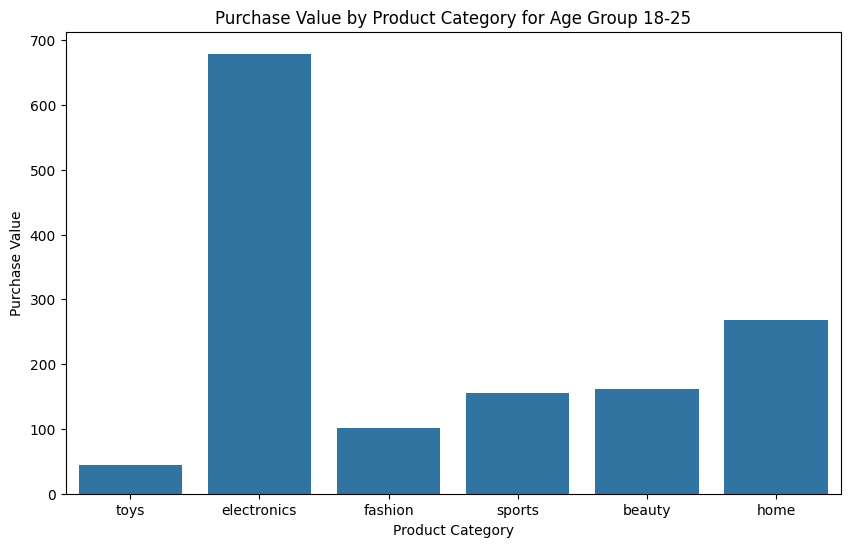

In [175]:
# Across what categories are the Age group 18-25 customers spending the most ? 

merged = pd.merge(transactions, customers, on='customer_id', how='inner')

# Create age buckets
merged['age_group'] = pd.cut(
                            merged['age'],
                            bins=[0, 18, 25, 35, 45, 55, 100],
                            labels=['<18', '18-25', '26-35', '36-45', '46-55', '55+']
                            )

#Plot product category wise purchase value for age group 18-25
plt.figure(figsize=(10, 6))
sns.barplot(x='product_category', y='purchase_value', data=merged[merged['age_group'] == '18-25'], estimator= 'mean', errorbar=None)
plt.title('Purchase Value by Product Category for Age Group 18-25') 
plt.xlabel('Product Category')
plt.ylabel('Purchase Value')
plt.show()

**Customer Acquistion by Source - Analysing the conversion rate for each source**

In [176]:
#customer acqusition by source

merged_1 = pd.merge(sessions, customers, on='customer_id', how='inner')

customer_acquisition_by_channel = merged_1.groupby('traffic_source')['customer_id'].nunique().sort_values(ascending=False)
print(customer_acquisition_by_channel)

traffic_source
paid       7601
email      7564
organic    7535
direct     7493
social     7406
Name: customer_id, dtype: int64


In [177]:
#How many customers converted from each traffic source and what is the conversion rate for each traffic source ?

conversion_by_source = (
                            sessions.groupby('traffic_source')
                            .agg(
                                converted=('converted', 'sum'),
                                total_sessions=('converted', 'count'),
                                conversion_rate=('converted', 'mean')
                            )
                        )

conversion_by_source['conversion_rate'] = (conversion_by_source['conversion_rate']).round(4) * 100

print(conversion_by_source.sort_values('conversion_rate', ascending=False))


                converted  total_sessions  conversion_rate
traffic_source                                            
organic              1886           14092            13.38
email                1880           14077            13.36
direct               1847           14045            13.15
paid                 1804           14098            12.80
social               1762           13788            12.78


**Analysing the Customer retention rates**

In [178]:
# Customers analysis by loyality dimension
customers.groupby(['customer_status'])['customer_id'].nunique().sort_values(ascending=False)
percentage_loyalty = (customers.groupby(['customer_status'])['customer_id'].nunique() / customers['customer_id'].nunique()) * 100
print(percentage_loyalty.sort_values(ascending=False))

customer_status
one_time    40.58
repeat      35.29
loyal       14.52
vip          4.87
churned      4.74
Name: customer_id, dtype: float64


**Refund Amount - effect on Revenue**

In [179]:
#calculating the refund value across categories and countries
merged = pd.merge(transactions, customers, on='customer_id', how='inner')
refund_value_by_reason = merged[merged['is_refunded'] == 1].groupby(['refund_reason'])['purchase_value'].sum().sort_values(ascending=False)
refund_value_by_category_reason = merged[merged['is_refunded'] == 1].groupby(['refund_reason', 'product_category'])['purchase_value'].sum()
print(refund_value_by_reason)
print(refund_value_by_category_reason)


refund_reason
late_delivery    221392.82
damaged          215165.32
wrong_item       211900.58
changed_mind     207721.25
Name: purchase_value, dtype: float64
refund_reason  product_category
changed_mind   beauty               23019.24
               electronics         104258.25
               fashion              13266.41
               home                 38508.84
               sports               22046.68
               toys                  6621.83
damaged        beauty               22522.45
               electronics         100787.88
               fashion              13871.81
               home                 47389.75
               sports               24763.79
               toys                  5829.64
late_delivery  beauty               27203.90
               electronics         104990.59
               fashion              15478.64
               home                 42785.76
               sports               23879.07
               toys                  7054.86

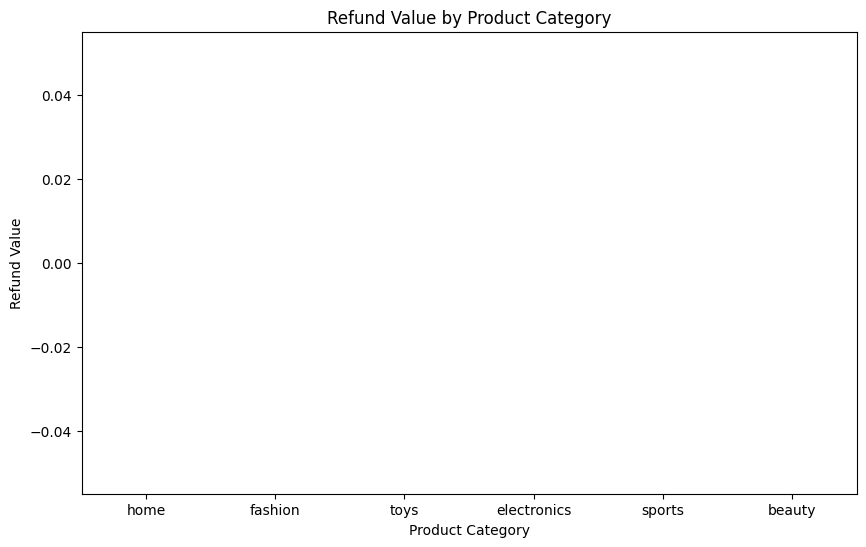

In [4]:
#graph for refund value by category
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

merged = pd.merge(transactions, customers, on='customer_id', how='inner')
merged['refund_value_by_category'] = merged[merged['is_refunded'] == 1].groupby(['product_category'])['purchase_value'].sum()

plt.figure(figsize=(10, 6))
sns.barplot(x='product_category', y='refund_value_by_category', data=merged, estimator= 'mean', errorbar=None)
plt.title('Refund Value by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Refund Value')
plt.show()

**Insights :**
1) Age group between 18-25 are the highest spenders and they spend on the Category 'Electronics'
2) This age group is spending almost similar across the countries with Netherlands being the highest followed by France and Germany.
3) The conversion rates are higher from the traffic sources - Organic and email
4) 60% of the customers are returning back to the site for purchases, marketing can focus on turning the 40% one-time customers into repeat customers. Also, can target turning repeat customers to turn into loyal customers by running some campaigns.
5) The category with highest refund value and the highest revenue is 'Electronics', this cam be seen as revenue protection opportunity and try to eliminate obvious reasons like damaged, wrong_item and late_delivery.